# Trade-offs in Optimal Design: Information against Cost

`optimal_experiment` finds the *most informative* experiment. It is rarely the
experiment you should run. The most informative experiment may take thirty
hours, or sit at conditions that make nothing you can sell, or run the reactor
hotter than you would like. What a planner actually needs to know is the
**exchange rate**: how much information does each hour, each percent of yield,
each degree cost?

`design_tradeoff` answers that by tracing the **Pareto front** between the
information criterion and a second objective, with the ε-constraint method
{cite:p}`Haimes1971,Miettinen1999`: hold the second objective to a level ε,
find the optimal design subject to it, and sweep ε. Every point on the curve is
an optimal design in its own right, and the axes are in units you can reason
about -- hours, yield -- rather than in the arbitrary weight a weighted sum would
need.

Information is reported as **efficiency** relative to the unconstrained optimum.
For D-optimality that is $(\det F / \det F^\star)^{1/p}$, and it has a concrete
meaning: a design with efficiency 0.5 needs **twice as many replicates** to
estimate the parameters as precisely as the optimum does.

Two examples, chosen because they come out very differently:

1. **Duration.** How long should a kinetic experiment run? (A steep front, and a
   surprising answer once time is priced in.)
2. **Production.** Can a batch that has to make saleable product still teach us
   something? (A nearly flat front: yes, almost for free.)


In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

import discopt.modeling as dm
from discopt.estimate import Experiment, ExperimentModel
from discopt.doe import compute_fim, design_tradeoff, optimal_experiment


## 1. How long should the experiment run?

A batch kinetics experiment for $A \xrightarrow{k_1} B \xrightarrow{k_2} C$ at
fixed temperature, with current estimates $k_1 = 0.3$ h⁻¹ and $k_2 = 0.05$ h⁻¹.
We can draw **three samples** and assay $B$ and $C$ in each; the design is the
three sampling times, anywhere in 0.1-40 h. The experiment's *duration* is the
last sampling time -- that is how long the reactor is tied up.


In [2]:
THETA = {"k1": 0.3, "k2": 0.05}


class SamplingSchedule(Experiment):
    def create_model(self, k1=0.3, k2=0.05):
        m = dm.Model("abc")
        k1v = m.continuous("k1", lb=1e-3, ub=10.0)
        k2v = m.continuous("k2", lb=1e-3, ub=10.0)
        times = {f"t{i}": m.continuous(f"t{i}", lb=0.1, ub=40.0) for i in (1, 2, 3)}
        responses = {}
        for name, t in times.items():
            b = k1v / (k2v - k1v) * (dm.exp(-k1v * t) - dm.exp(-k2v * t))
            responses[f"B_{name}"] = b
            responses[f"C_{name}"] = 1.0 - dm.exp(-k1v * t) - b
        return ExperimentModel(
            model=m,
            unknown_parameters={"k1": k1v, "k2": k2v},
            design_inputs=times,
            responses=responses,
            measurement_error=dict.fromkeys(responses, 0.01),
        )


schedule = SamplingSchedule()
BOUNDS = {f"t{i}": (0.1, 40.0) for i in (1, 2, 3)}

best = optimal_experiment(schedule, THETA, BOUNDS)
print("D-optimal sampling times:", {k: round(v, 2) for k, v in sorted(best.design.items())})
print(f"duration: {max(best.design.values()):.1f} h")


D-optimal sampling times: {'t1': 3.14, 't2': 3.14, 't3': 23.55}
duration: 23.5 h


The D-optimal schedule samples early (around 3 h, to catch $B$ near its
peak for $k_1$) and then waits a full day for the slow degradation $k_2$ to
reveal itself. Is that last sample worth the wait? Sweep the duration:


In [3]:
def duration(design):
    return max(design.values())


front = design_tradeoff(
    schedule,
    THETA,
    BOUNDS,
    tradeoff=duration,
    sense="minimize",          # shorter is better
    n_levels=12,
    tradeoff_name="duration [h]",
)
print(front.summary())


Trade-off: determinant information vs duration [h] (minimize)
  duration [h] efficiency         t1         t2         t3
----------------------------------------------------------
         23.55      1.000      3.145      3.145      23.55
         21.66      0.995      3.155      3.155      21.66
         19.77      0.980      3.168      3.168      19.77
         17.87      0.952      3.185      3.185      17.87
         15.98      0.909      3.205      3.205      15.98
         14.09      0.850      14.09      14.09      3.102
          12.2      0.782       12.2       12.2        3.1
         10.31      0.703      10.31      10.31      3.087 <- knee
         8.417      0.610      8.417      8.417      3.068
         6.526      0.495      6.526      3.137      6.526
         4.635      0.376      4.635      4.635      4.635
         2.743      0.173      2.743      2.743      2.743
        0.8518      0.012     0.8518     0.8518     0.8518


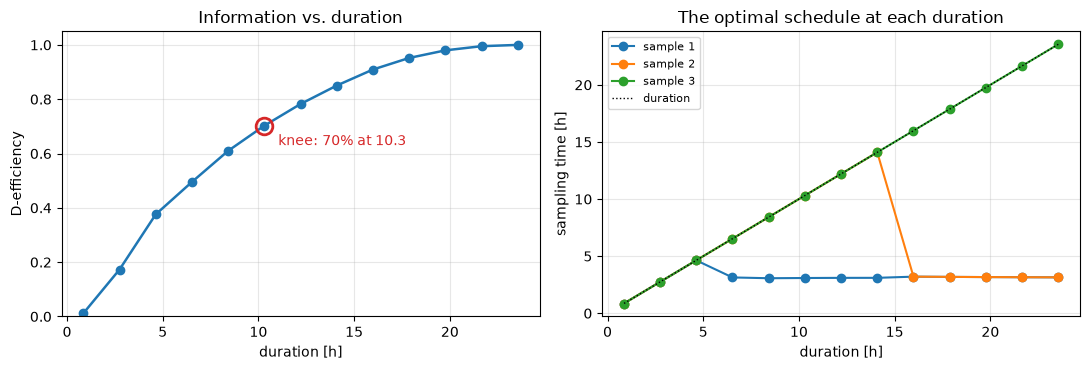

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
front.plot(ax=ax1)
ax1.set_title("Information vs. duration")

pts = front.front
d = np.array([p.tradeoff_value for p in pts])
for i in (1, 2, 3):
    ax2.plot(d, [sorted(p.design.values())[i - 1] for p in pts], "o-", label=f"sample {i}")
ax2.plot(d, d, "k:", lw=1, label="duration")
ax2.set_xlabel("duration [h]")
ax2.set_ylabel("sampling time [h]")
ax2.set_title("The optimal schedule at each duration")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Read the front from the right. Cutting the experiment from a day to about
half a day costs only about a fifth of the information -- the late sample was
worth less than its wait. Below that, the front steepens: there is no longer
time for $C$ to accumulate, and the samples collapse together. The knee (circled)
marks where the curve bends.

The right panel shows the *design* changing along the front. Long experiments
park two samples at the $B$ peak and send one late. Below about 15 h the
schedule flips -- one sample stays at the peak and two go to the end of the
window -- and in the shortest experiments all three crowd at the end, where the
most has happened.

### Pricing the time

The knee is geometry, not economics. To decide, put a price on time. If
experiments can be run back to back, what matters is **information per hour of
reactor time**. Efficiency adds up over replicates (two runs at efficiency 0.5
match one optimal run), so information per hour is proportional to
$\text{efficiency} / (\text{duration} + \text{overhead})$, where the overhead is
the fixed time to charge, heat and clean the reactor between runs:


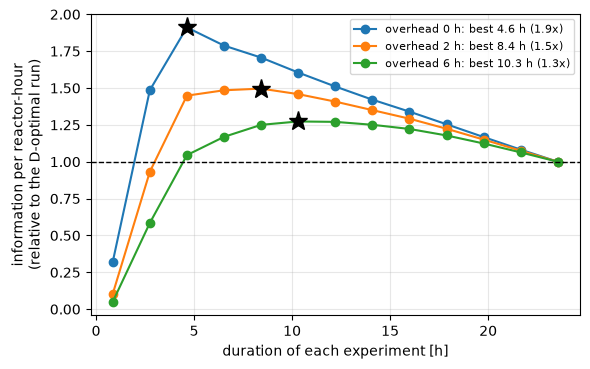

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.8))
d_ref = front.points[0].tradeoff_value
for overhead in (0.0, 2.0, 6.0):
    rate = np.array([p.efficiency / (p.tradeoff_value + overhead) for p in pts])
    rate /= 1.0 / (d_ref + overhead)          # relative to repeating the D-optimal run
    k = int(np.argmax(rate))
    ax.plot(d, rate, "o-", label=f"overhead {overhead:g} h: best {d[k]:.1f} h ({rate[k]:.1f}x)")
    ax.plot(d[k], rate[k], "*", ms=14, color="k")
ax.axhline(1.0, color="k", ls="--", lw=1)
ax.set_xlabel("duration of each experiment [h]")
ax.set_ylabel("information per reactor-hour\n(relative to the D-optimal run)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


This is the compelling part. With no overhead, a sequence of short
experiments learns the kinetics **almost twice as fast** per reactor-hour as
repeating the "optimal" day-long experiment. The overhead shifts the best
duration upward -- with six hours of turnaround, longer runs win back some
ground -- but the D-optimal design is never the most efficient use of the
reactor. That conclusion is invisible to `optimal_experiment` alone, and it took
one call to `design_tradeoff`.


## 2. Can a production batch also teach?

Back to the series reaction from the previous notebook,
[multi-objective model-based optimization](multi-objective-model-based.ipynb):
temperature and batch time are the design, yield of $B$ and impurity $C$ the
responses, four Arrhenius parameters unknown. Five scouting runs have been made
and the parameters estimated. The next batch has to ship product -- but we would
still like it to sharpen the kinetic model.

The second objective is now a **response**: pass its name, and
`design_tradeoff` predicts it at the nominal parameters. Yield is something we
want *more* of, so `sense="maximize"`, and the levels are lower bounds. The five
earlier runs enter as `prior_fim` -- information already in hand -- so the sweep
asks what the *next* run adds.


In [6]:
R, T_REF = 8.314e-3, 330.0


class SeriesReaction(Experiment):
    def create_model(self, k1=0.5, E1=40.0, k2=0.05, E2=60.0):
        m = dm.Model("series")
        k1v = m.continuous("k1", lb=0.2, ub=5.0)
        E1v = m.continuous("E1", lb=10.0, ub=150.0)
        k2v = m.continuous("k2", lb=0.005, ub=0.15)
        E2v = m.continuous("E2", lb=10.0, ub=150.0)
        T = m.continuous("T", lb=310.0, ub=350.0)
        t = m.continuous("t", lb=0.25, ub=4.0)
        K1 = k1v * dm.exp(-E1v / R * (1 / T - 1 / T_REF))
        K2 = k2v * dm.exp(-E2v / R * (1 / T - 1 / T_REF))
        B = K1 / (K2 - K1) * (dm.exp(-K1 * t) - dm.exp(-K2 * t))
        return ExperimentModel(
            model=m,
            unknown_parameters={"k1": k1v, "E1": E1v, "k2": k2v, "E2": E2v},
            design_inputs={"T": T, "t": t},
            responses={"yield_B": B, "impurity_C": 1 - dm.exp(-K1 * t) - B},
            measurement_error={"yield_B": 0.01, "impurity_C": 0.002},
        )


series = SeriesReaction()
theta_hat = {"k1": 0.99, "E1": 50.3, "k2": 0.0805, "E2": 89.8}   # from the five runs
scouting = [(312, 0.5), (348, 0.5), (312, 3.5), (348, 3.5), (330, 2.0)]
prior = sum(compute_fim(series, theta_hat, {"T": T, "t": t}).fim for T, t in scouting)

production = design_tradeoff(
    series,
    theta_hat,
    {"T": (310.0, 350.0), "t": (0.25, 4.0)},
    tradeoff="yield_B",
    sense="maximize",
    prior_fim=prior,
    n_levels=7,
)
print(production.summary())


Trade-off: determinant information vs yield_B (maximize)
       yield_B efficiency          T          t
-----------------------------------------------
         0.691      1.000      333.6          4
        0.7103      0.999      332.8          4
        0.7296      0.995      331.9          4
        0.7489      0.989        331          4
        0.7682      0.979        330          4 <- knee
        0.7875      0.965      328.8          4
        0.8068      0.944      327.3          4
        0.8261      0.907      325.1          4


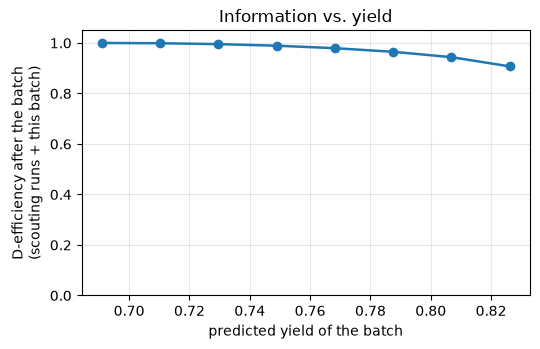

highest-yield point: yield 0.826 at T = 325.1 K, t = 4.00 h -> efficiency 0.91


In [7]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
production.plot(ax=ax, annotate_knee=False)
ax.set_xlabel("predicted yield of the batch")
ax.set_ylabel("D-efficiency after the batch\n(scouting runs + this batch)")
ax.set_title("Information vs. yield")
plt.tight_layout()
plt.show()

top = production.points[-1]
print(f"highest-yield point: yield {top.tradeoff_value:.3f} at T = {top.design['T']:.1f} K, "
      f"t = {top.design['t']:.2f} h -> efficiency {top.efficiency:.2f}")


With `prior_fim`, efficiency measures the information of the whole campaign
*after* the batch, scouting runs included -- what the final parameter precision
will be. That flatters the batch: some of the flatness is information already in
hand. To see what the batch *itself* contributes, compare the gain in
$\log\det F$ over the prior with the gain of the most informative batch:


In [8]:
log_det_prior = np.linalg.slogdet(prior)[1]
best_gain = production.reference.criterion_value - log_det_prior
print(f"{'yield':>6s} {'efficiency':>10s} {'share of the best gain':>24s}")
for p in production.points:
    share = (p.criterion_value - log_det_prior) / best_gain
    print(f"{p.tradeoff_value:6.3f} {p.efficiency:10.3f} {share:24.2f}")


 yield efficiency   share of the best gain
 0.691      1.000                     1.00
 0.710      0.999                     1.00
 0.730      0.995                     0.99
 0.749      0.989                     0.98
 0.768      0.979                     0.95
 0.788      0.965                     0.92
 0.807      0.944                     0.87
 0.826      0.907                     0.78


Either way the front is shallow. The most informative next batch already
yields about 0.69. A batch at 0.79 -- most of the way to the best yield the
process can deliver -- still contributes over 90 % of that batch's information
gain, and even the highest-yield batch contributes about 80 %. Here the
trade-off is cheap, and the planning conclusion is the opposite of the first
example: don't schedule a separate "learning" batch at all -- run production
near the high-yield end of this curve and let it double as the experiment.

The two examples together are the point of tracing the front rather than
guessing: the same question ("what does the second objective cost in
information?") can have a steep answer or a flat one, and you cannot tell which
without computing it.


## Using `design_tradeoff`

```python
front = design_tradeoff(
    experiment, theta, design_bounds,
    tradeoff=...,            # a response name, or g(design) -> float
    sense="minimize",        # or "maximize" (levels become lower bounds)
    n_levels=8,              # or levels=[...] explicitly
    criterion="determinant", # any optimal_experiment criterion
    prior_fim=...,           # and any other optimal_experiment argument,
    response_bounds=...,     # applied at every level
)
front.points      # each: level, tradeoff_value, efficiency, design, result
front.knee        # the max-distance-to-chord compromise
front.summary()   # text table
front.plot()      # efficiency vs. the second objective
front.rows()      # list of dicts, e.g. for pandas.DataFrame
```

Levels are solved from loose to tight, each warm-started from the previous
design; a point that a tighter design beats is re-solved from it, and anything
still dominated is flagged `on_front=False`.

**Related.** For several *process* objectives (yield and impurity themselves,
rather than information about them), see
[multi-objective model-based optimization](multi-objective-model-based.ipynb).
For trading precision against *model discrimination*, see
`discriminate_compound` in [model discrimination](model-discrimination.ipynb).
For designs that stay efficient across parameter uncertainty, see
`robust_optimal_experiment`.
